### Skin Disease Classification

In this project, we use machine learning to classify six types of erythemato-squamous skin diseases based on clinical and histopathological features. The notebook covers three main parts:

1. **Exploratory Data Analysis (EDA):** Understand the dataset, check its quality, and explore the patterns in the features.
2. **Machine Learning:** Train and compare different classification models to see how accurately they can identify the diseases. We also discuss which model would be a suitable choice for practical use.
3. **Clinical Suggestions:** Discuss how the findings from the analysis could help doctors when examining patients.

**Disease classes**

The target column in the CSV contains numerical labels from 1 to 6. The corresponding disease names are taken from the public UCI documentation because the names are not included in the dataset itself.

| Class | Disease |
|---|---|
| 1 | Psoriasis |
| 2 | Seborrheic dermatitis |
| 3 | Lichen planus |
| 4 | Pityriasis rosea |
| 5 | Chronic dermatitis |
| 6 | Pityriasis rubra pilaris |

### Importing Libraries and Setting Up

Before starting the analysis, we import the libraries needed for data handling, visualization, and machine learning. We also set the random seed to 42 so that the results remain consistent whenever the notebook is run again.

In [1]:
# Basic Python library
import itertools

# Libraries for working with data
import numpy as np
import pandas as pd

# Libraries for creating graphs and charts
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Machine learning libraries
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, recall_score
)
from sklearn.inspection import permutation_importance

# Set the plot style and random seed
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

We first load the dataset into a pandas DataFrame. One thing to notice is that the missing values in the Age column are represented by a question mark (`?`). We use `na_values="?"` while reading the CSV so pandas can recognize these as missing values (`NaN`).

Some of the column names also contain spelling mistakes and hyphens. Rather than changing them, we leave the names as they appear in the original dataset to avoid any issues when referring to the columns later.

We also use `df.info()` to get a quick overview of the dataset, including its column names, data types, and missing values.

In [2]:
# Read the CSV file and treat question marks as missing values
df = pd.read_csv("dataset_35_dermatology (1).csv", na_values="?")
df.shape

(366, 35)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   erythema                                  366 non-null    int64  
 1   scaling                                   366 non-null    int64  
 2   definite_borders                          366 non-null    int64  
 3   itching                                   366 non-null    int64  
 4   koebner_phenomenon                        366 non-null    int64  
 5   polygonal_papules                         366 non-null    int64  
 6   follicular_papules                        366 non-null    int64  
 7   oral_mucosal_involvement                  366 non-null    int64  
 8   knee_and_elbow_involvement                366 non-null    int64  
 9   scalp_involvement                         366 non-null    int64  
 10  family_history                        

The dataset contains **366 rows and 35 columns**. Out of these, 34 columns are input features and the remaining column, `class`, is the target we want to predict.

Most columns contain integer values. The Age column is stored as a decimal number and has 358 available values, which means that 8 patients have missing age information.

Next, let's take a closer look at the actual data. We display the first few rows to understand how the values are stored, followed by some basic statistical information about the features.

These statistics will help us get an idea of the value ranges and identify anything unusual before moving on to the analysis.

In [4]:
# Display the first few records in the dataset
df.head()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


In [5]:
df.describe()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,...,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,358.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,...,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,36.296089,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,...,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,15.324557,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,25.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,35.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,49.750000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,75.000000,6.000000


A few things stand out from the summary:

- Most of the features have values ranging from 0 to 3. The `family_history` column is different because it only contains 0 and 1. Also, `eosinophils_in_the_infiltrate` does not have any values above 2 in this dataset.
- The Age column has an average of 36.30 years and a median of 35 years. The youngest recorded age is 0, while the oldest is 75. The value of 0 looks unusual, so we will check it more closely.
- Not all features appear equally often. For example, `follicular_horn_plug` has a very low mean of 0.10, whereas `acanthosis` has a mean of 1.96.

This gives us an initial idea of how the features are distributed and what we should pay attention to during the next steps.

The dataset has 11 clinical features, 22 histopathological features, and one additional feature called `Age`.

We now separate the clinical and histopathological feature names into two lists. We also create a dictionary to connect the numerical class labels with their corresponding disease names.

The `assert` statement checks whether the columns are arranged as expected in the original dataset.

In [6]:
# Separate the clinical and histopathological features
clinical_features = list(df.columns[:11])
histo_features = list(df.columns[11:33])

# Match each class number with its disease name
class_names = {
    1: "Psoriasis",
    2: "Seborrheic dermatitis",
    3: "Lichen planus",
    4: "Pityriasis rosea",
    5: "Chronic dermatitis",
    6: "Pityriasis rubra pilaris",
}

class_ids = list(class_names)

print("Number of clinical features:", len(clinical_features))
print("Number of histopathological features:", len(histo_features))

Number of clinical features: 11
Number of histopathological features: 22


Before moving further, we should check whether the dataset has any quality issues.

Here, we look for missing values, duplicate records, unusually recorded ages, and the number of patients in each disease class. This will help us understand the condition of the data before using it for machine learning.

In [7]:
# Check missing values and duplicate records
missing = df.isna().sum()

print("Columns containing missing values:")
print(missing[missing > 0].to_string())

print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check whether any patient has an age recorded as zero
print("Rows with Age == 0:", (df["Age"] == 0).sum())

# Count the number of patients in each disease class
class_counts = df["class"].value_counts().sort_index()

class_table = pd.DataFrame({
    "class": class_counts.index,
    "disease": [class_names[c] for c in class_counts.index],
    "patients": class_counts.values,
    "percent": (class_counts.values / len(df) * 100).round(1),
})

display(class_table)

Columns containing missing values:
Age    8

Number of duplicate rows: 0
Rows with Age == 0: 1


,class,disease,patients,percent
0,1,Psoriasis,112,30.6
1,2,Seborrheic dermatitis,61,16.7
2,3,Lichen planus,72,19.7
3,4,Pityriasis rosea,49,13.4
4,5,Chronic dermatitis,52,14.2
5,6,Pityriasis rubra pilaris,20,5.5


From these checks, we can make a few observations:

- The only column with missing values is `Age`, which has 8 missing entries.
- We did not find any duplicate rows in the dataset.
- One patient has an age recorded as 0. We decided to leave this value as it is rather than making an assumption about the correct age. It could be a data-entry mistake, so we will mention it as a limitation in the conclusion. We will also check which disease class this patient belongs to during the EDA.
- The number of patients in each class is 112, 61, 72, 49, 52, and 20, respectively. Psoriasis has the highest number of patients (30.6%), while Pityriasis rubra pilaris has the lowest (5.5%).

This also gives us an early indication that the dataset is not evenly distributed across all six classes.

### Exploratory Data Analysis (EDA)

In this section, we explore the dataset to get a better understanding of the features and how they relate to the different disease classes.

EDA is only used to understand the data. We are not training or testing any machine learning models here. Since this part is descriptive, we use the complete dataset. The actual train-test split will be done later in Section 3.

We will start by looking at the number of patients in each disease class using a count plot.

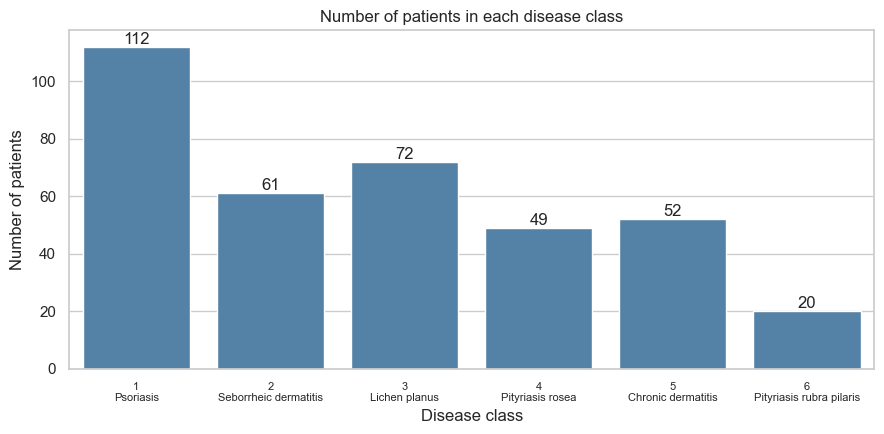

In [8]:
# Visualize how many patients belong to each disease class
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(data=df, x="class", order=class_ids,color="steelblue", ax=ax)
ax.set_xticks(range(len(class_ids)))
ax.set_xticklabels([f"{c}\n{class_names[c]}" for c in class_ids],fontsize=8)
for container in ax.containers:
    ax.bar_label(container)
ax.set_title("Number of patients in each disease class")
ax.set_xlabel("Disease class")
ax.set_ylabel("Number of patients")
plt.tight_layout()
plt.show()

**Observation:**

Looking at the chart, we can see that the dataset has an imbalance between the disease classes. Psoriasis has 112 patients, whereas Pityriasis rubra pilaris has only 20. This means the largest class is about 5.6 times bigger than the smallest one.

We need to keep this in mind when building our models. To handle this, we will use stratified splitting and also compare macro F1 scores and individual class results instead of depending only on overall accuracy.

Next, we look at the age distribution of the patients. We use a histogram with a KDE curve to see how ages are spread across the dataset and whether there are any unusual values.

We will also display a summary table showing the age statistics separately for each disease class. The `count` column represents the number of patients with a recorded age.

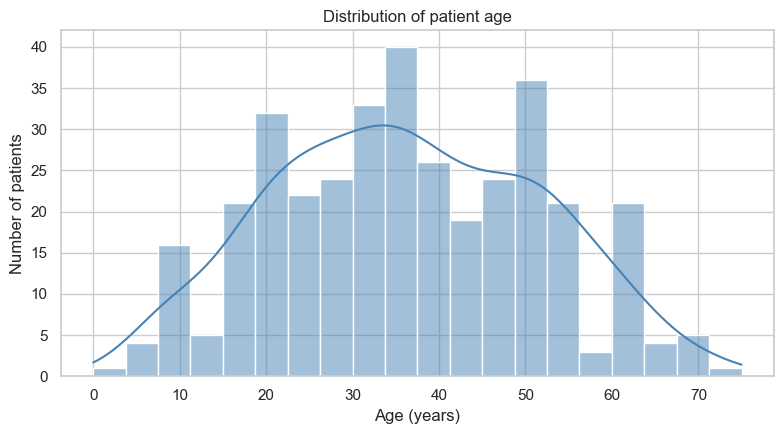

,count,mean,median,min,max
1 Psoriasis,111,39.4,39.0,0.0,75.0
2 Seborrheic dermatitis,60,35.5,34.0,10.0,70.0
3 Lichen planus,71,40.0,40.0,16.0,65.0
4 Pityriasis rosea,48,35.3,35.0,12.0,70.0
5 Chronic dermatitis,48,36.7,35.5,8.0,70.0
6 Pityriasis rubra pilaris,20,10.2,9.5,7.0,22.0


In [9]:
# Age histogram with KDE, then Age summary per class
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df["Age"].dropna(), bins=20, kde=True, color="steelblue", ax=ax)
ax.set_title("Distribution of patient age")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of patients")
plt.tight_layout()
plt.show()
age_by_class = df.groupby("class")["Age"].agg(["count", "mean", "median", "min", "max"]).round(1)
age_by_class.index = [f"{c} {class_names[c]}" for c in age_by_class.index]
display(age_by_class)

**Observation:**

- Most patients are between approximately 25 and 50 years old. The 25th percentile is 25 years and the 75th percentile is 49.75 years. The oldest patient in the dataset is 75.
- Class 6 (Pityriasis rubra pilaris) has a noticeably different age distribution. Its average age is 10.2 years, with a median of 9.5 and an age range of 7 to 22. For the other five classes, the average ages fall between 35.3 and 40 years.
- We can also see that the age of 0 belongs to a patient in class 1 (Psoriasis). As mentioned earlier, we are keeping this value unchanged and treating it as a possible data-entry issue.

Now let's look at the 11 clinical features in the dataset. These features represent signs that can be observed or reported during a patient's examination, even before a biopsy is performed.

Instead of creating a separate chart for every feature, we display them in two groups using count plots. Each bar represents the number of patients with a particular score. The scores range from 0 (absent) to 3 (strongest), while `family_history` is recorded using only 0 and 1.

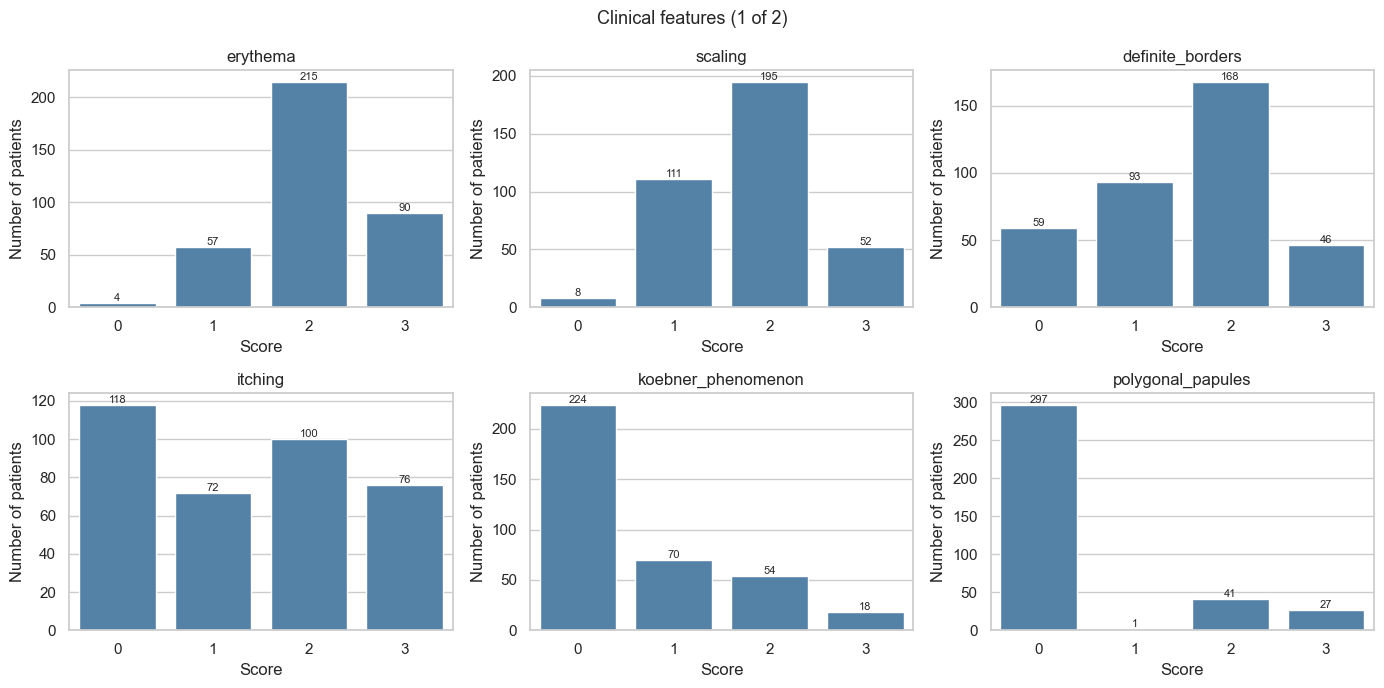

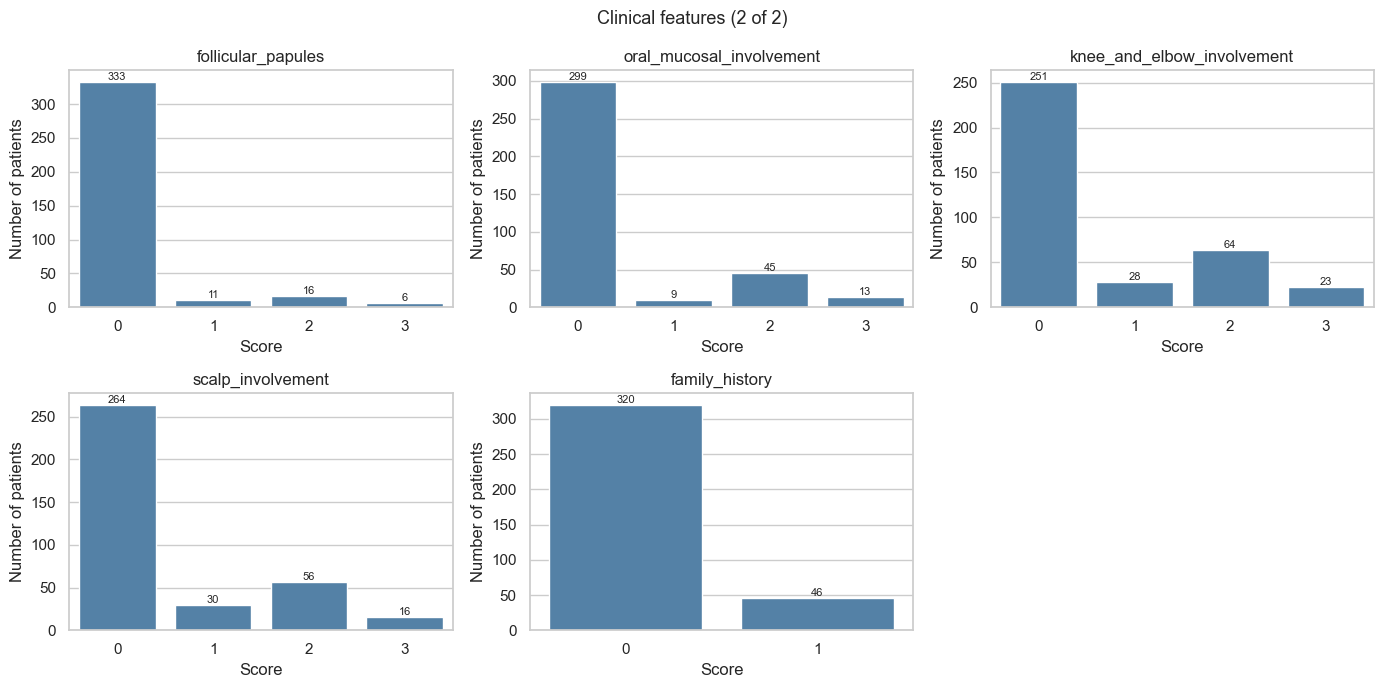

In [10]:
# Count plots for the 11 clinical features, split into two grids
def plot_count_grid(features, title):
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    axes = axes.ravel()
    for ax, feat in zip(axes, features):
        order = [0, 1] if feat == "family_history" else [0, 1, 2, 3]
        sns.countplot(data=df, x=feat, order=order, color="steelblue", ax=ax)
        for container in ax.containers:
            ax.bar_label(container, fontsize=8)
        ax.set_title(feat)
        ax.set_xlabel("Score")
        ax.set_ylabel("Number of patients")
    for ax in axes[len(features):]:   # hide unused panels
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

plot_count_grid(clinical_features[:6], "Clinical features (1 of 2)")
plot_count_grid(clinical_features[6:], "Clinical features (2 of 2)")

**Observation:**

- `erythema` and `scaling` are present in almost all patients. Only 4 patients have an erythema score of 0, and 8 have a scaling score of 0. Most patients have a score of 2 for these features (215 for erythema and 195 for scaling).
- Some of the other features are absent in a large number of patients. For example, `follicular_papules` has a score of 0 in 333 patients, `oral_mucosal_involvement` in 299 patients, and `polygonal_papules` in 297 patients.
- The scores for `itching` are more spread out across the dataset. We have 118 patients with a score of 0, 72 with a score of 1, 100 with a score of 2, and 76 with a score of 3.
- For `family_history`, 46 patients have a value of 1, while the remaining 320 have a value of 0.

Overall, the clinical features vary quite a bit in how frequently they appear among the patients.

Since family history is recorded for only a small number of patients, it is worth checking whether it is more common in certain disease groups.

The table below shows the number of patients with and without a family history for each class. It also calculates the percentage of patients with a family history within each disease class.

In [11]:
# Family history by disease class (counts and share of each class)
family_table = pd.crosstab(df["class"], df["family_history"])
family_table.columns = ["no family history", "family history"]
family_table["class size"] = family_table.sum(axis=1)
family_table["% with family history"] = (family_table["family history"] / family_table["class size"] * 100).round(1)
family_table.index = [f"{c} {class_names[c]}" for c in family_table.index]
display(family_table)

,no family history,family history,class size,% with family history
1 Psoriasis,80,32,112,28.6
2 Seborrheic dermatitis,58,3,61,4.9
3 Lichen planus,71,1,72,1.4
4 Pityriasis rosea,49,0,49,0.0
5 Chronic dermatitis,52,0,52,0.0
6 Pityriasis rubra pilaris,10,10,20,50.0


**Observation:**

Family history appears more frequently in two particular disease classes.

- For Psoriasis, 32 out of 112 patients (28.6%) have a recorded family history.
- For Pityriasis rubra pilaris, the number is 10 out of 20 patients (50%).

In comparison, family history is much less common in the other classes. We found it in 3 out of 61 patients with Seborrheic dermatitis (4.9%) and 1 out of 72 patients with Lichen planus (1.4%). None of the patients with Pityriasis rosea or Chronic dermatitis have a recorded family history.

Adding these numbers together gives us the total of 46 patients with a family history that we observed earlier.

Now the 22 histopathological features. This heatmap shows the **average score** of each feature in each disease class. Dark cells mean the feature is strongly present on average. Features that are dark in only one column are good "signatures" for that disease.

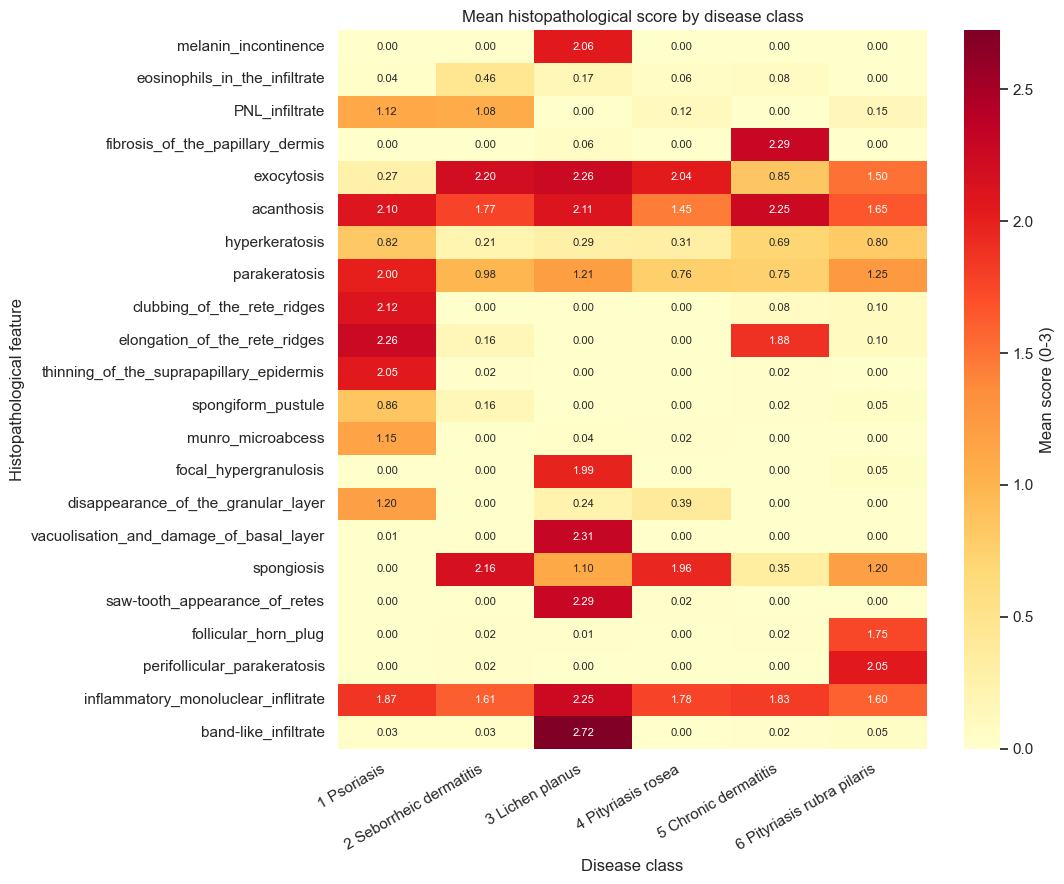

In [12]:
# Heatmap of mean histopathological score per class
mean_histo = df.groupby("class")[histo_features].mean().T
mean_histo.columns = [f"{c} {class_names[c]}" for c in mean_histo.columns]

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(mean_histo, annot=True, fmt=".2f", cmap="YlOrRd", annot_kws={"size": 8},
            cbar_kws={"label": "Mean score (0-3)"}, ax=ax)
ax.set_title("Mean histopathological score by disease class")
ax.set_xlabel("Disease class")
ax.set_ylabel("Histopathological feature")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Observation:**

The heatmap shows that some histopathological features are much more common in certain disease classes than in others.

- For Lichen planus, features such as `melanin_incontinence` (2.06), `band-like_infiltrate` (2.72), `saw-tooth_appearance_of_retes` (2.29), `vacuolisation_and_damage_of_basal_layer` (2.31), and `focal_hypergranulosis` (1.99) have relatively high average scores. These values are close to zero in most of the other classes.
- `fibrosis_of_the_papillary_dermis` stands out in Chronic dermatitis, with an average score of 2.29, compared with a maximum of 0.06 in the other classes.
- For Pityriasis rubra pilaris, `follicular_horn_plug` (1.75) and `perifollicular_parakeratosis` (2.05) are the more noticeable features. Their average scores are almost zero in the remaining classes.
- Psoriasis has higher scores for `clubbing_of_the_rete_ridges` (2.12) and `thinning_of_the_suprapapillary_epidermis` (2.05).
- One interesting thing is that Seborrheic dermatitis and Pityriasis rosea have similar scores for `spongiosis` (2.16 and 1.96) and `exocytosis` (2.20 and 2.04). This similarity could make it harder for the models to distinguish between these two diseases. We will check this again when evaluating the models later.

These patterns give us a better idea of which features may help distinguish one disease from another.

The heatmap gives us the average scores, but it does not show exactly how many patients received each score.

To get a clearer picture, we now calculate the number of patients with scores of 0, 1, 2, and 3 for every histopathological feature. This will help us see which findings are common, which are rare, and whether all four score values are used.

In [13]:
# Value counts (0-3) for every histopathological feature
histo_value_counts = (
    df[histo_features].apply(pd.Series.value_counts).fillna(0).astype(int).T
)
histo_value_counts.columns = [f"score {c}" for c in histo_value_counts.columns]
histo_value_counts["total"] = histo_value_counts.sum(axis=1)
display(histo_value_counts)

,score 0,score 1,score 2,score 3,total
melanin_incontinence,296,8,46,16,366
eosinophils_in_the_infiltrate,324,33,9,0,366
PNL_infiltrate,235,69,55,7,366
fibrosis_of_the_papillary_dermis,312,8,23,23,366
exocytosis,118,57,129,62,366
acanthosis,10,71,210,75,366
hyperkeratosis,227,90,44,5,366
parakeratosis,86,118,132,30,366
clubbing_of_the_rete_ridges,252,19,61,34,366
elongation_of_the_rete_ridges,198,23,95,50,366


**Observation:**

After looking at the score counts, we noticed a few things:

- Some histopathological findings are quite rare. For example, `follicular_horn_plug` has a score of 0 for 344 patients, while `perifollicular_parakeratosis` has a score of 0 for 345 patients.
- On the other hand, a few features are present in most patients. `acanthosis` has only 10 patients with a score of 0, and `inflammatory_monoluclear_inflitrate` has only 13.
- `eosinophils_in_the_infiltrate` never reaches a score of 3. Its values are distributed across 324 zeros, 33 ones, and 9 twos.
- `exocytosis` uses all four score levels, with counts of 118, 57, 129, and 62, respectively.
- Every histopathological feature has a total of 366 entries. This means there are no missing values in these features.

This check helps confirm that the histopathological part of the dataset is complete.

Next, we look at the relationships between the features using correlation heatmaps.

We create two separate heatmaps: one for the clinical features along with `Age`, and another for the histopathological features.

Correlation values close to +1 indicate that two features tend to increase together, while values close to 0 suggest a weaker relationship. We also list the strongest feature pairs below the heatmaps so that we can refer to their exact correlation values.

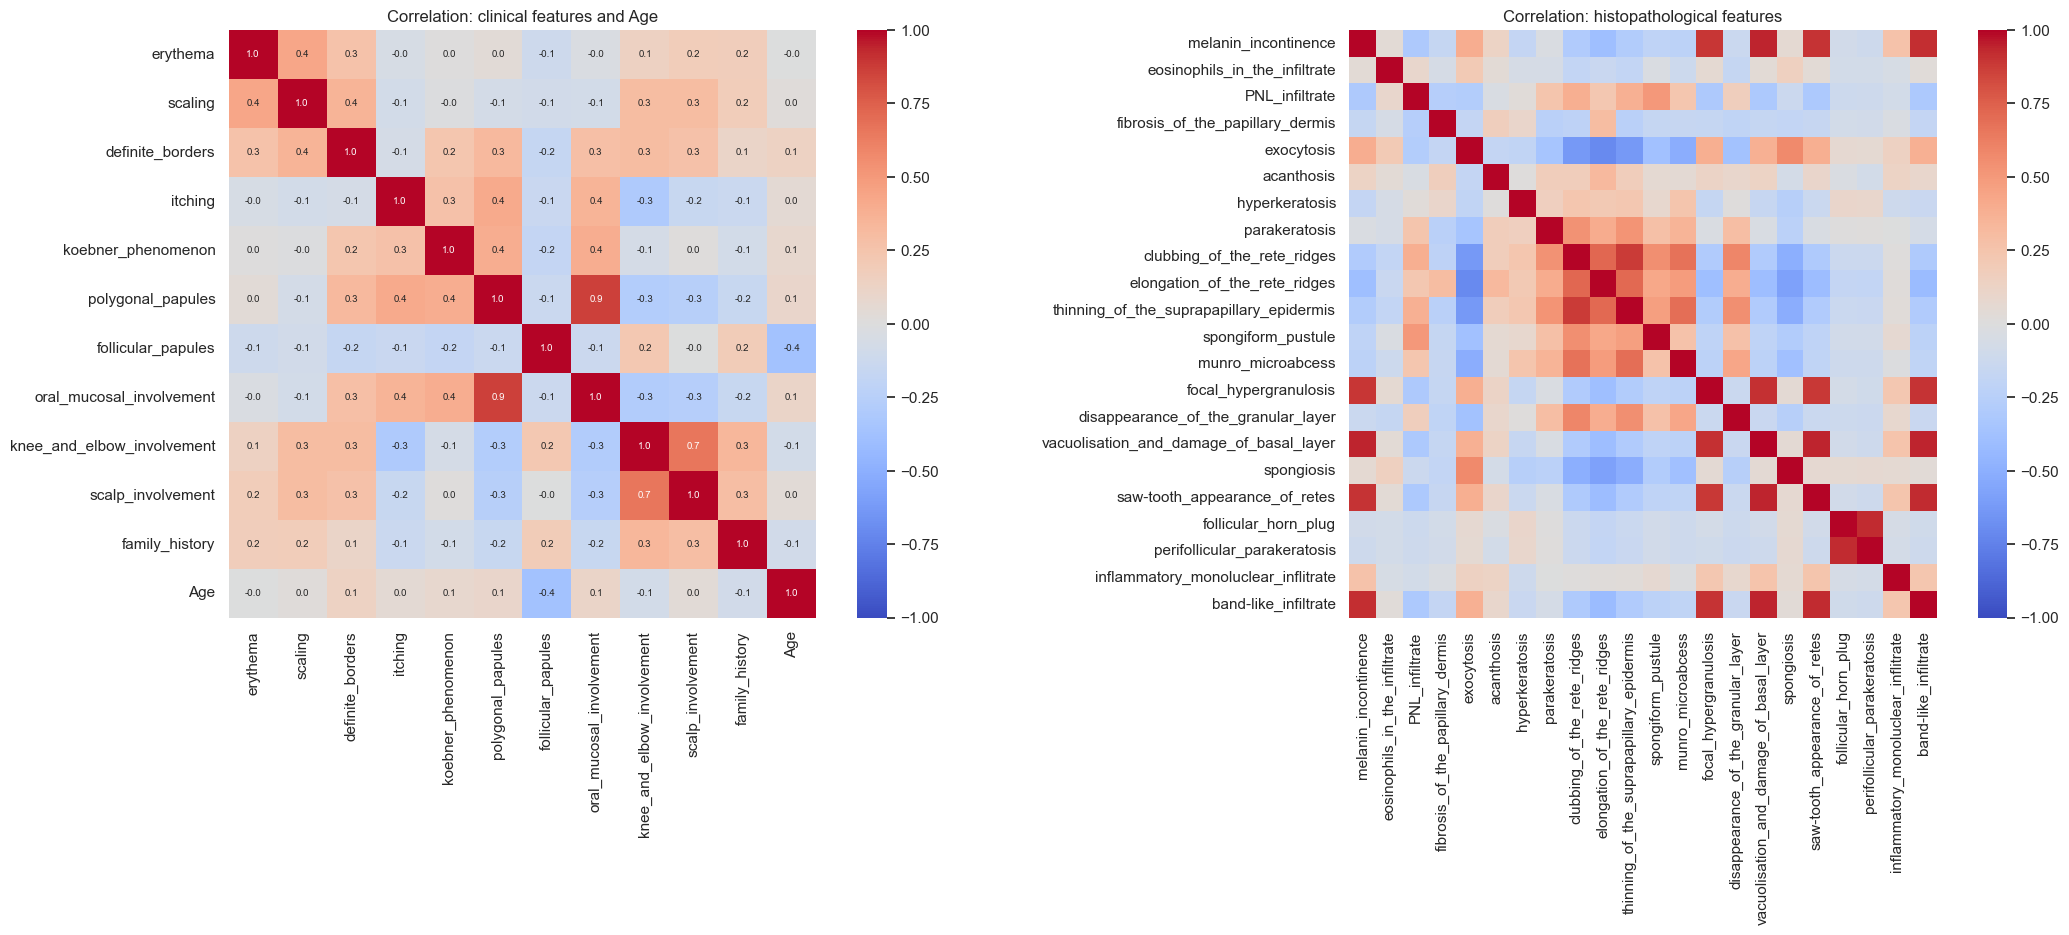

Strongest clinical/Age pairs:


,feature_1,feature_2,correlation
0,polygonal_papules,oral_mucosal_involvement,0.87
1,knee_and_elbow_involvement,scalp_involvement,0.66
2,erythema,scaling,0.44
3,itching,polygonal_papules,0.41
4,koebner_phenomenon,polygonal_papules,0.39
5,koebner_phenomenon,oral_mucosal_involvement,0.39


Strongest histopathological pairs:


,feature_1,feature_2,correlation
0,melanin_incontinence,vacuolisation_and_damage_of_basal_layer,0.94
1,vacuolisation_and_damage_of_basal_layer,saw-tooth_appearance_of_retes,0.94
2,vacuolisation_and_damage_of_basal_layer,band-like_infiltrate,0.94
3,follicular_horn_plug,perifollicular_parakeratosis,0.93
4,saw-tooth_appearance_of_retes,band-like_infiltrate,0.93
5,melanin_incontinence,band-like_infiltrate,0.92


In [14]:
# Correlation heatmaps side by side
clinical_corr = df[clinical_features + ["Age"]].corr()
histo_corr = df[histo_features].corr()

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap(clinical_corr, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 7}, square=True, ax=axes[0])
axes[0].set_title("Correlation: clinical features and Age")
sns.heatmap(histo_corr, cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=axes[1])
axes[1].set_title("Correlation: histopathological features")
plt.tight_layout()
plt.show()

# Strongest pairs, listed so the observations can quote exact values
def top_pairs(corr, n=6):
    mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)   # upper triangle, no diagonal
    pairs = corr.where(mask).stack().reset_index()
    pairs.columns = ["feature_1", "feature_2", "correlation"]
    order = pairs["correlation"].abs().sort_values(ascending=False).index
    return pairs.loc[order].head(n).round(2).reset_index(drop=True)

print("Strongest clinical/Age pairs:")
display(top_pairs(clinical_corr))
print("Strongest histopathological pairs:")
display(top_pairs(histo_corr))

**Observation:**

The correlation heatmaps show some interesting relationships between the features.

- Among the clinical features, `polygonal_papules` and `oral_mucosal_involvement` have the strongest correlation at 0.87. Another noticeable pair is `knee_and_elbow_involvement` and `scalp_involvement`, with a correlation of 0.66. The next strongest pair, `erythema` and `scaling`, has a lower value of 0.44. Age does not appear among the strongest pairs.
- The histopathological features show some much stronger relationships. `vacuolisation_and_damage_of_basal_layer` has a correlation of 0.94 with `melanin_incontinence`, `saw-tooth_appearance_of_retes`, and `band-like_infiltrate`. Also, `follicular_horn_plug` and `perifollicular_parakeratosis` have a correlation of 0.93.
- These relationships make sense because some features tend to appear together as part of the same disease pattern. For example, several of the strongly correlated features are associated with Lichen planus.

One thing to keep in mind is that highly correlated features may contain overlapping information. This can become important when we examine feature importance in Section 6.

### Preparing the Data and Avoiding Data Leakage

Before training the models, we need to prepare the dataset properly.

One important issue to avoid is **data leakage**. This happens when information from the test data is accidentally used during training or preprocessing. When that happens, the model may appear to perform better than it actually does.

To prevent this, we first separate the training and test data. Any preprocessing values, such as the median used to fill missing ages, will be calculated using the training data only.

**Step 1:** Separate the input features (`X`) from the target column (`y`). At this stage, the missing values in `Age` are left as they are.

In [15]:
# Step 1: separate features and target (Age still contains NaN)
X = df.drop(columns="class")
y = df["class"]
print("X shape:", X.shape, "| y shape:", y.shape)
print("Missing Age values in X:", X["Age"].isna().sum())

X shape: (366, 34) | y shape: (366,)
Missing Age values in X: 8


**Step 2:** Split the dataset into training and testing sets using an 80:20 ratio.

We use `stratify=y` so that the proportions of the six disease classes remain similar in both sets. This is especially important because some classes have relatively few patients.

We also keep the original feature sets as `X_train_raw` and `X_test_raw`. These versions are not modified and still contain the missing age values. We will use the training version for cross-validation later.

In [16]:
# Step 2: stratified 80/20 split. The "_raw" versions keep the original NaN in Age.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train_raw.shape, "| Test:", X_test_raw.shape)
print("Missing Age in train:", X_train_raw["Age"].isna().sum(),
      "| in test:", X_test_raw["Age"].isna().sum())

split_counts = pd.DataFrame({"train": y_train.value_counts().sort_index(),
                             "test": y_test.value_counts().sort_index()})
split_counts.index = [f"{c} {class_names[c]}" for c in split_counts.index]
display(split_counts)

Train: (292, 34) | Test: (74, 34)
Missing Age in train: 5 | in test: 3


,train,test
1 Psoriasis,89,23
2 Seborrheic dermatitis,49,12
3 Lichen planus,57,15
4 Pityriasis rosea,39,10
5 Chronic dermatitis,42,10
6 Pityriasis rubra pilaris,16,4


After splitting the data, we have 292 patients in the training set and 74 patients in the test set.

Out of the 8 missing age values, 5 are in the training set and 3 are in the test set. All six disease classes are represented in both sets.

The smallest class, Pityriasis rubra pilaris, has 16 patients in the training set and only 4 in the test set. This is something we should remember when interpreting the final test results.

**Step 3:** We now handle the missing values in the Age column.

For this, we calculate the median age using only the training data. We then use that same median to fill the missing ages in both the training and test sets.

Using the training median for both sets helps us avoid data leakage because the test data is not used to calculate the value.

The updated datasets will be stored as `X_train` and `X_test`.

In [17]:
# Step 3: median Age from the TRAINING set only, applied to both sets
age_median_train = X_train_raw["Age"].median()
print("Median Age (training set only):", age_median_train)

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()
X_train["Age"] = X_train["Age"].fillna(age_median_train)
X_test["Age"] = X_test["Age"].fillna(age_median_train)

Median Age (training set only): 36.0


The median age calculated from the training set is 36.0. This is slightly different from the median of 35.0 that we obtained earlier when looking at the complete dataset.

This difference shows why we calculate the median after splitting the data. If we had used the entire dataset, information from the test set would also have influenced the preprocessing step.

**Step 4:** Finally, we check whether any missing values are still present in the prepared training and test datasets.

We use an `assert` statement to make sure both datasets are completely filled. If any missing values remain, the notebook will raise an error instead of silently continuing.

In [18]:
# Step 4: confirm that no missing values remain in the filled copies
print("Missing values in X_train:", int(X_train.isna().sum().sum()))
print("Missing values in X_test: ", int(X_test.isna().sum().sum()))
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0

Missing values in X_train: 0
Missing values in X_test:  0


Both datasets now have zero missing values, so the age imputation step is complete.

We have not applied scaling to the entire dataset at this stage. Instead, scaling will be included inside the pipelines for the models that need it. This way, the scaler is fitted only on the appropriate training data during cross-validation and does not get information from the validation or test data.

### Setting Up Cross-Validation

Before comparing the models, we want to get a more reliable idea of how they perform. Rather than depending on a single train-validation split, we use **10-fold cross-validation**.

In this approach, the training data is divided into 10 smaller groups. Each group is used once for validation, while the remaining 9 groups are used to train the model.

We use `StratifiedKFold` with shuffling and a random seed of 42. This helps maintain a similar distribution of disease classes across the folds.

An important point is that cross-validation is performed only on the 292 training records. The test set remains untouched until Section 5.

We also prepare three machine learning pipelines:

- **Logistic Regression:** Uses median imputation, standard scaling, and then Logistic Regression. Scaling is useful here because Age has a much wider range than the other features.
- **Random Forest:** Uses median imputation followed by the Random Forest model. Scaling is not necessary for this model because tree-based models are not affected by differences in feature scales in the same way.
- **SVM:** Uses median imputation, standard scaling, and then the SVM classifier. Since SVM is based on distances, scaling the features is important.

We leave `class_weight` as `None` for now. We will experiment with balanced class weights separately in Section 7.

The Logistic Regression and SVM models are deterministic with these settings. Random Forest is also given a fixed random seed so its results can be reproduced.

In [19]:
# Cross-validation splitter and the three model pipelines
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

def build_models(class_weight=None):
    """Return fresh, unfitted pipelines. class_weight is only used in Section 7."""
    return {
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, class_weight=class_weight)),
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(n_estimators=100, random_state=42,
                                             class_weight=class_weight)),
        ]),
        "SVM": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVC(class_weight=class_weight)),
        ]),
    }

models = build_models()
scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro"}
print("Models:", list(models))

Models: ['Logistic Regression', 'Random Forest', 'SVM']


Now that the pipelines are ready, we can run cross-validation for all three models.

We pass `X_train_raw` instead of the already filled dataset because we want the imputation step to happen separately inside each fold. This ensures that the median is calculated using only the training portion of that particular fold.

For evaluation, we use two metrics: accuracy and macro F1 score. Accuracy tells us the overall percentage of correct predictions, while macro F1 calculates the average F1 score across all six classes, giving each class equal importance.

After running the 10 folds, we calculate the mean and standard deviation for both metrics.

In [20]:
# 10-fold CV on the training data with the original NaN in Age (X_train_raw)
cv_rows = []
for name, pipe in models.items():
    res = cross_validate(pipe, X_train_raw, y_train, cv=cv, scoring=scoring)
    cv_rows.append({
        "Model": name,
        "Accuracy mean (%)": res["test_accuracy"].mean() * 100,
        "Accuracy std (%)": res["test_accuracy"].std() * 100,
        "Macro F1 mean (%)": res["test_f1_macro"].mean() * 100,
        "Macro F1 std (%)": res["test_f1_macro"].std() * 100,
    })
cv_summary = pd.DataFrame(cv_rows).set_index("Model").round(2)
display(cv_summary)

,Accuracy mean (%),Accuracy std (%),Macro F1 mean (%),Macro F1 std (%)
Model,,,,
Logistic Regression,97.93,1.69,97.59,1.99
Random Forest,97.94,2.28,97.32,3.04
SVM,97.93,1.69,97.65,1.93


**Observation:**

The cross-validation results are very close for all three models.

- **Accuracy:** Logistic Regression achieves 97.93%, Random Forest achieves 97.94%, and SVM achieves 97.93%. The difference between their average accuracies is almost negligible.
- **Macro F1:** The scores are 97.59% for Logistic Regression, 97.32% for Random Forest, and 97.65% for SVM. These differences are also quite small compared with the variation between folds.
- **Consistency:** Random Forest has a slightly higher standard deviation, which means its performance varies more across the different folds.

Each validation fold contains around 29 patients. Even one incorrect prediction can change a fold's accuracy by approximately 3.4 percentage points.

Based on these results, it would be difficult to confidently say that one model is better than the others. All three perform very similarly, although Random Forest shows slightly more variation between folds.

### Training the Models and Evaluating Test Performance

We have finished comparing the models using cross-validation. Now it is time to check how they perform on data they have not seen before.

Each pipeline will be trained using the full training dataset (`X_train`, `y_train`) and then evaluated on the separate test dataset.

We will look at the overall accuracy as well as the classification report for each disease class.

The classification report includes three useful measures:

- **Precision:** Out of all the cases predicted as a particular disease, how many were correct?
- **Recall:** Out of all the actual patients with that disease, how many did the model correctly identify?
- **F1-score:** A combined measure of precision and recall.

This will help us understand not just how many predictions are correct, but also how the models perform for individual diseases.

In [21]:
# Fit each pipeline on the full training set and evaluate once on the test set
class_labels = [class_names[c] for c in class_ids]
predictions = {}
test_rows = []

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred
    test_rows.append({
        "Model": name,
        "Test accuracy (%)": accuracy_score(y_test, y_pred) * 100,
        "Errors": int((y_pred != y_test).sum()),
        "Test patients": len(y_test),
    })
    print("=" * 70)
    print(name)
    print(classification_report(y_test, y_pred, labels=class_ids,
                                target_names=class_labels, digits=3))

display(pd.DataFrame(test_rows).set_index("Model").round(2))

Logistic Regression
                          precision    recall  f1-score   support

               Psoriasis      1.000     1.000     1.000        23
   Seborrheic dermatitis      1.000     0.833     0.909        12
           Lichen planus      1.000     0.933     0.966        15
        Pityriasis rosea      0.769     1.000     0.870        10
      Chronic dermatitis      1.000     1.000     1.000        10
Pityriasis rubra pilaris      1.000     1.000     1.000         4

                accuracy                          0.959        74
               macro avg      0.962     0.961     0.957        74
            weighted avg      0.969     0.959     0.961        74

Random Forest
                          precision    recall  f1-score   support

               Psoriasis      1.000     1.000     1.000        23
   Seborrheic dermatitis      0.909     0.833     0.870        12
           Lichen planus      1.000     1.000     1.000        15
        Pityriasis rosea      0.818   

,Test accuracy (%),Errors,Test patients
Model,,,
Logistic Regression,95.95,3,74
Random Forest,95.95,3,74
SVM,97.30,2,74


**Observation:**

The test results are quite good for all three models.

- Logistic Regression achieves 95.95% accuracy with 3 incorrect predictions.
- Random Forest also achieves 95.95% accuracy, with 3 incorrect predictions.
- SVM performs slightly better at 97.30%, with only 2 incorrect predictions.

Classes 1 (Psoriasis), 5 (Chronic dermatitis), and 6 (Pityriasis rubra pilaris) are classified perfectly by all three models.

The weaker results appear mainly in class 2 (Seborrheic dermatitis), where recall is 0.833 for all three models, and class 4 (Pityriasis rosea), where precision ranges from 0.769 to 0.833.

Overall, the models perform well, but distinguishing between certain disease classes still seems to be a challenge.

Accuracy gives us an overall idea of how well the models perform, but it does not tell us exactly where the incorrect predictions occur.

To understand this better, we use confusion matrices for all three models. Each row represents the actual disease class, while each column represents the class predicted by the model.

The values along the diagonal are correct predictions. Any values outside the diagonal represent cases where the model predicted the wrong disease.

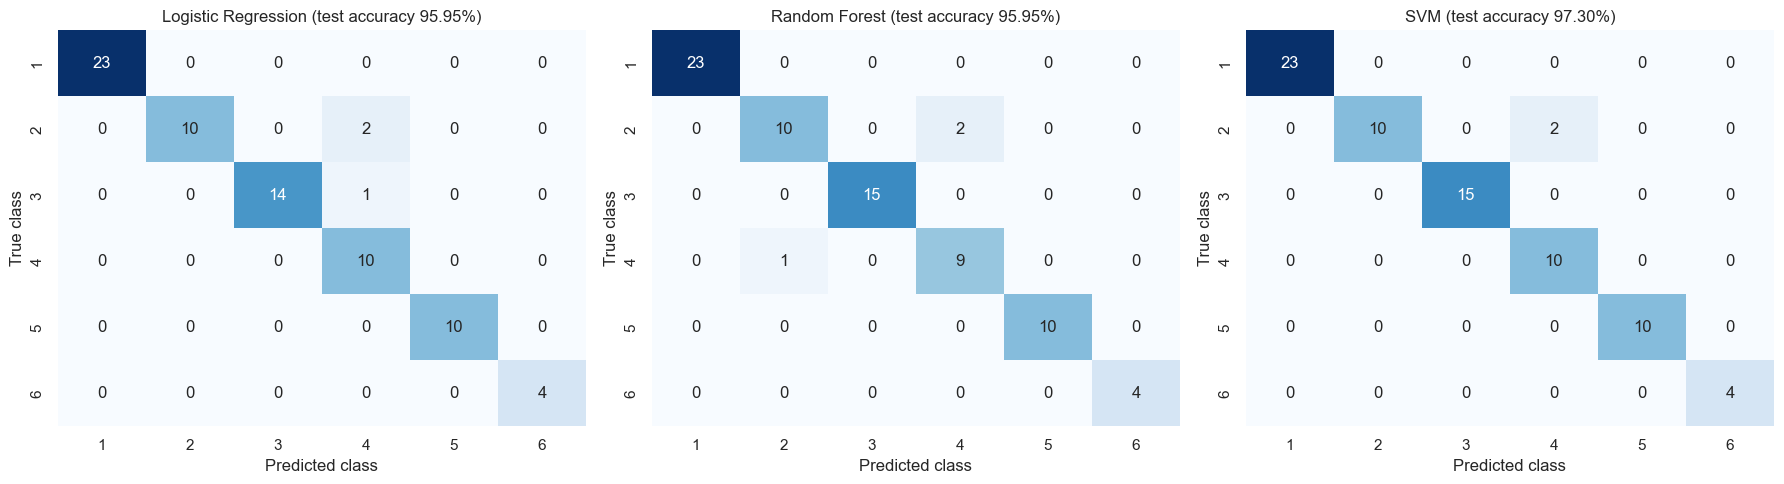

In [22]:
# Confusion matrices side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_ids)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_ids, yticklabels=class_ids, ax=ax)
    ax.set_title(f"{name} (test accuracy {accuracy_score(y_test, y_pred) * 100:.2f}%)")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
plt.tight_layout()
plt.show()

**Observation:**

Most of the values in the confusion matrices appear along the diagonal, which means that the majority of patients are classified correctly.

The few incorrect predictions are mainly related to classes 2 and 4. We can also see one case involving class 3 in the Logistic Regression results.

Since these errors are limited to a small number of patients, it is worth looking at the individual misclassified records to understand what happened.

To get a clearer idea of the model errors, we now list the patients who were classified incorrectly.

For each model, the table shows the actual disease class and the class predicted by the model. We also keep the original row index so that the records can be traced back to the dataset.

In [23]:
# Which test patients were misclassified, per model
for name, y_pred in predictions.items():
    wrong = (y_pred != y_test.values)
    errors = pd.DataFrame({
        "true class": [f"{c} {class_names[c]}" for c in y_test.values[wrong]],
        "predicted class": [f"{c} {class_names[c]}" for c in y_pred[wrong]],
    }, index=y_test.index[wrong])
    print(f"{name}: {wrong.sum()} errors")
    display(errors)

Logistic Regression: 3 errors


,true class,predicted class
143,3 Lichen planus,4 Pityriasis rosea
140,2 Seborrheic dermatitis,4 Pityriasis rosea
43,2 Seborrheic dermatitis,4 Pityriasis rosea


Random Forest: 3 errors


,true class,predicted class
328,4 Pityriasis rosea,2 Seborrheic dermatitis
140,2 Seborrheic dermatitis,4 Pityriasis rosea
43,2 Seborrheic dermatitis,4 Pityriasis rosea


SVM: 2 errors


,true class,predicted class
140,2 Seborrheic dermatitis,4 Pityriasis rosea
43,2 Seborrheic dermatitis,4 Pityriasis rosea


**Observation:**

Looking at the individual errors, we noticed that patients 140 and 43 actually had Seborrheic dermatitis, but all three models predicted Pityriasis rosea for them.

There were also two other incorrect predictions:

- Logistic Regression classified one Lichen planus patient (patient 143) as Pityriasis rosea.
- Random Forest classified one Pityriasis rosea patient (patient 328) as Seborrheic dermatitis.

This is interesting because Seborrheic dermatitis and Pityriasis rosea already showed similar patterns in the EDA, particularly for `spongiosis` and `exocytosis`. The models may be finding it difficult to separate these two diseases because of that overlap.

**Why we are not choosing a winner based only on test accuracy:**

The test set contains just 74 patients. This means that a single incorrect prediction changes the accuracy by around 1.4 percentage points.

SVM made one fewer error than the other two models, but that difference comes down to just one patient. It is not enough to confidently claim that SVM is a better model.

The cross-validation results also showed that all three models perform almost equally. Therefore, we will consider their overall performance and other practical factors before making a final recommendation.

### Understanding Feature Importance

Now that we have compared the models, let's take a look at which features have the biggest influence on their predictions.

For this, we use **permutation importance**. The idea is to shuffle the values of one feature and check how much the model's accuracy changes. If accuracy drops significantly, it suggests that the model depends more on that feature. If there is very little change, the feature may have less influence on its predictions.

We repeat this process 10 times for each feature and calculate the average importance using accuracy as the evaluation metric.

We perform this analysis using the training data only (`X_train`, `y_train`) for all three fitted pipelines. Since the pipelines already contain the imputer and scaler, we can calculate importance using the original features.

One important thing to remember is that feature importance does not tell us what causes a disease. It only tells us which features the model relies on when making predictions.

Finally, we display the 10 most important features based on their average importance across the three models.

In [24]:
# Permutation importance on the training data for all three fitted pipelines
perm_results = {}
for name, pipe in models.items():
    result = permutation_importance(pipe, X_train, y_train, n_repeats=10,
                                    random_state=RANDOM_STATE, scoring="accuracy")
    perm_results[name] = pd.Series(result.importances_mean, index=X_train.columns)

model_names = list(models)
perm_df = pd.DataFrame(perm_results)
perm_df["Average"] = perm_df[model_names].mean(axis=1)

top10_table = perm_df.sort_values("Average", ascending=False).head(10)
print("Top 10 features by average permutation importance (drop in accuracy):")
display(top10_table.round(4))

Top 10 features by average permutation importance (drop in accuracy):


,Logistic Regression,Random Forest,SVM,Average
koebner_phenomenon,0.0575,0.0688,0.0209,0.0491
fibrosis_of_the_papillary_dermis,0.0205,0.0113,0.0154,0.0158
spongiosis,0.0199,0.0041,0.0113,0.0118
disappearance_of_the_granular_layer,0.0274,0.0031,0.0003,0.0103
itching,0.0185,0.0021,0.0058,0.0088
PNL_infiltrate,0.0120,0.0021,0.0051,0.0064
spongiform_pustule,0.0017,0.0000,0.0014,0.0010
clubbing_of_the_rete_ridges,0.0007,0.0017,0.0003,0.0009
thinning_of_the_suprapapillary_epidermis,0.0007,0.0010,0.0007,0.0008
erythema,0.0017,0.0000,-0.0003,0.0005


**Observation:**

The feature importance results show that some features have a much greater influence on the models than others.

- `koebner_phenomenon` comes out as the most important feature, with an average importance of 0.0491. When this feature is shuffled, accuracy drops by 6.88 percentage points for Random Forest, 5.75 for Logistic Regression, and 2.09 for SVM.
- The next important features are `fibrosis_of_the_papillary_dermis` (0.0158) and `spongiosis` (0.0118). Other features in the top group include `disappearance_of_the_granular_layer`, `itching`, and `PNL_infiltrate`.
- After the first few features, the importance scores decrease quite quickly. From the seventh feature onwards, the average importance is around 0.001 or lower. Some values are even zero or slightly negative, such as `erythema` for SVM.
- The overall importance scores are relatively small. One possible reason is that several features are correlated with each other. As we saw earlier, when one feature is shuffled, another related feature may still provide similar information to the model.

So, while the top features appear to be useful for making predictions, we should be careful when interpreting the smaller differences in importance.

Next, we compare the top 10 features selected by each model.

We use Python sets to check which features appear in all three models, which ones are shared between two models, and which features appear only in one model's top 10 list.

This gives us a better idea of whether the models are relying on similar features or learning different patterns from the dataset.

In [25]:
# Overlap of the top-10 lists, computed with code
top10_sets = {
    name: set(perm_df[name].sort_values(ascending=False).head(10).index)
    for name in model_names
}

print("In the top 10 of ALL three models:")
print(sorted(set.intersection(*top10_sets.values())))

print("\nShared by each pair of models (includes features that are in all three):")
for a, b in itertools.combinations(model_names, 2):
    print(f"  {a} & {b}: {sorted(top10_sets[a] & top10_sets[b])}")

print("\nUnique to one model:")
for name in model_names:
    others = set.union(*(top10_sets[m] for m in model_names if m != name))
    print(f"  {name}: {sorted(top10_sets[name] - others)}")

In the top 10 of ALL three models:
['PNL_infiltrate', 'fibrosis_of_the_papillary_dermis', 'itching', 'koebner_phenomenon', 'spongiosis']

Shared by each pair of models (includes features that are in all three):
  Logistic Regression & Random Forest: ['PNL_infiltrate', 'disappearance_of_the_granular_layer', 'fibrosis_of_the_papillary_dermis', 'itching', 'koebner_phenomenon', 'spongiosis']
  Logistic Regression & SVM: ['PNL_infiltrate', 'fibrosis_of_the_papillary_dermis', 'itching', 'koebner_phenomenon', 'spongiosis']
  Random Forest & SVM: ['PNL_infiltrate', 'fibrosis_of_the_papillary_dermis', 'itching', 'koebner_phenomenon', 'spongiform_pustule', 'spongiosis', 'thinning_of_the_suprapapillary_epidermis']

Unique to one model:
  Logistic Regression: ['band-like_infiltrate', 'elongation_of_the_rete_ridges', 'erythema', 'scaling']
  Random Forest: ['clubbing_of_the_rete_ridges', 'munro_microabcess']
  SVM: ['Age', 'follicular_papules', 'perifollicular_parakeratosis']


**Observation:**

The comparison shows that the three models share several important features.

- Five features appear in the top 10 of all three models: `PNL_infiltrate`, `fibrosis_of_the_papillary_dermis`, `itching`, `koebner_phenomenon`, and `spongiosis`.
- Logistic Regression and Random Forest share 8 features in their top 10 lists.
- Logistic Regression and SVM share 6 features, while Random Forest and SVM also share 6.
- A few features appear in only one model's list. Logistic Regression has `elongation_of_the_rete_ridges`, Random Forest has `clubbing_of_the_rete_ridges`, and SVM has `Age`, `follicular_papules`, and `perifollicular_parakeratosis`.

Even though there are some differences, the main features are quite similar across all three models. The differences near the bottom of the rankings should not be given too much importance because their scores are already very small.

So far, we have compared only the top 10 features. Now we want to see how similar the complete feature rankings are across all three models.

For this, we calculate the **Spearman rank correlation** using all 34 features. This measures how similarly two models rank the features, rather than comparing their actual importance values.

A value close to 1 means the rankings are very similar, while a value close to 0 means there is little relationship between them.

In [26]:
# Compare the feature rankings using Spearman correlation
spearman_corr = perm_df[model_names].corr(method="spearman")
display(spearman_corr.round(2))

,Logistic Regression,Random Forest,SVM
Logistic Regression,1.00,0.67,0.51
Random Forest,0.67,1.00,0.67
SVM,0.51,0.67,1.00


**Observation:**

The Spearman correlation values show a moderate level of agreement between the models.

- Logistic Regression and Random Forest have a correlation of 0.67.
- Random Forest and SVM also have a correlation of 0.67.
- Logistic Regression and SVM have a correlation of 0.51.

This suggests that the models generally agree on the more important features, but their rankings become less similar when we look at features with lower importance scores.

To make the differences easier to compare, we now create a bar chart showing the top 10 features and their importance scores for each model.

The features are arranged according to their average importance, so we can compare the three models side by side and see which features stand out.

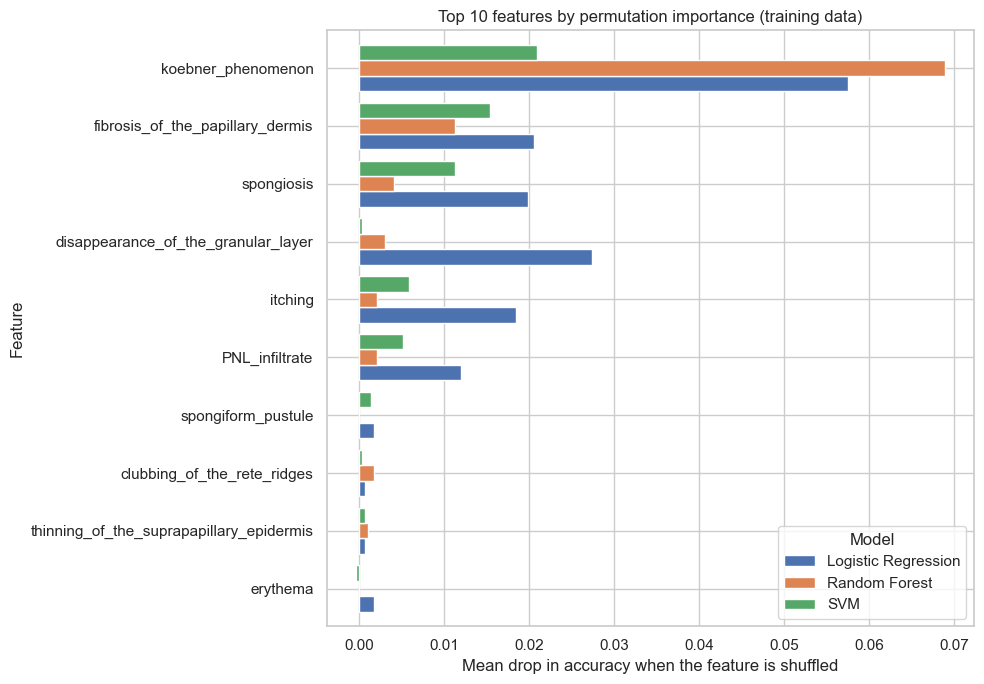

In [27]:
# Bar chart of the top 10 features (ordered by average importance)
plot_data = top10_table[model_names].iloc[::-1]   # reverse so the largest is on top
ax = plot_data.plot(kind="barh", figsize=(10, 7), width=0.8)
ax.set_title("Top 10 features by permutation importance (training data)")
ax.set_xlabel("Mean drop in accuracy when the feature is shuffled")
ax.set_ylabel("Feature")
ax.legend(title="Model", loc="lower right")
plt.tight_layout()
plt.show()

**Observation:**

The chart makes it clear that `koebner_phenomenon` has the highest importance, particularly for Random Forest and Logistic Regression.

We can also see that some features have quite different importance scores depending on the model. For example, `disappearance_of_the_granular_layer` has an importance of 0.0274 for Logistic Regression but only 0.0003 for SVM.

This shows that the models do not always rely on the same features to make their predictions. Also, these results describe how the models behave on the training data. They should not be interpreted as evidence that a particular feature causes a disease.

### Experimenting with Balanced Class Weights

In this section, we try one additional experiment to see whether balanced class weights can improve the model results.

As we noticed earlier, some disease classes have fewer patients than others. Because of this, a model might pay more attention to the larger classes during training.

To check whether this affects our results, we use `class_weight="balanced"`. This gives more importance to the smaller classes while training the models.

We repeat the same 10-fold cross-validation using the same folds for both the original and balanced versions of the three models.

Apart from comparing accuracy and macro F1, we also check the recall scores for classes 2, 4, and 6, since these are among the smaller classes in our dataset.

We use out-of-fold predictions to calculate the recall for each class and then compare the changes in percentage points between the two settings.

In [28]:
# OPTIONAL EXPERIMENT: class_weight="balanced" vs. unweighted, same CV folds
small_classes = [2, 4, 6]
settings = {"unweighted": build_models(), "balanced": build_models(class_weight="balanced")}

score_rows, recall_rows = [], []
for setting, model_set in settings.items():
    for name, pipe in model_set.items():
        res = cross_validate(pipe, X_train_raw, y_train, cv=cv, scoring=scoring)
        score_rows.append({
            "Model": name, "Setting": setting,
            "Accuracy mean (%)": res["test_accuracy"].mean() * 100,
            "Macro F1 mean (%)": res["test_f1_macro"].mean() * 100,
        })
        # Out-of-fold predictions -> recall per class (pooled over all folds)
        oof_pred = cross_val_predict(pipe, X_train_raw, y_train, cv=cv)
        recalls = recall_score(y_train, oof_pred, labels=class_ids, average=None)
        recall_rows.append({
            "Model": name, "Setting": setting,
            **{f"Class {c} recall (%)": recalls[class_ids.index(c)] * 100 for c in small_classes},
        })

print("Overall CV scores:")
display(pd.DataFrame(score_rows).set_index(["Model", "Setting"]).round(2))

recall_df = pd.DataFrame(recall_rows).set_index(["Model", "Setting"])
print("Per-class recall for the smaller classes (2 = Seborrheic dermatitis, "
      "4 = Pityriasis rosea, 6 = Pityriasis rubra pilaris):")
display(recall_df.round(1))

recall_change = (recall_df.xs("balanced", level="Setting")
                 - recall_df.xs("unweighted", level="Setting"))
print("Change in recall with balanced weights (percentage points):")
display(recall_change.round(1))

Overall CV scores:


,,Accuracy mean (%),Macro F1 mean (%)
Model,Setting,,
Logistic Regression,unweighted,97.93,97.59
Random Forest,unweighted,97.94,97.32
SVM,unweighted,97.93,97.65
Logistic Regression,balanced,97.93,97.59
Random Forest,balanced,97.95,97.45
SVM,balanced,97.93,97.65


Per-class recall for the smaller classes (2 = Seborrheic dermatitis, 4 = Pityriasis rosea, 6 = Pityriasis rubra pilaris):


,,Class 2 recall (%),Class 4 recall (%),Class 6 recall (%)
Model,Setting,,,
Logistic Regression,unweighted,93.9,92.3,100.0
Random Forest,unweighted,95.9,92.3,93.8
SVM,unweighted,91.8,94.9,100.0
Logistic Regression,balanced,93.9,92.3,100.0
Random Forest,balanced,95.9,92.3,93.8
SVM,balanced,91.8,94.9,100.0


Change in recall with balanced weights (percentage points):


,Class 2 recall (%),Class 4 recall (%),Class 6 recall (%)
Model,,,
Logistic Regression,0.0,0.0,0.0
Random Forest,0.0,0.0,0.0
SVM,0.0,0.0,0.0


**Observation: The balanced class weights did not make a noticeable difference.**

After comparing both settings, we found that the overall performance remained almost the same.

- Logistic Regression and SVM produced identical accuracy scores of 97.93% with and without balanced weights. Their macro F1 scores also remained almost unchanged at 97.59% and 97.65%, respectively.
- Random Forest showed only a very small change. Its accuracy increased from 97.94% to 97.95%, while macro F1 increased from 97.32% to 97.45%.
- More importantly, the recall scores for classes 2, 4, and 6 did not change for any of the three models.

For example, Logistic Regression continued to achieve 93.9% recall for class 2 (46 out of 49 patients). Class 6 recall also remained at 100% for Logistic Regression and SVM, and 93.8% for Random Forest.

In this experiment, applying balanced weights did not improve the recognition of the smaller classes. One possible reason is that the models were already performing well on these classes.

Based on these results, we decided to keep the original unweighted models for our main comparison. This does not mean balanced class weights are never useful; they simply did not provide an improvement with this particular dataset and model setup.

### Clinical Suggestions for Doctors (Task 3)

Based on the patterns we found during the analysis, there are a few points that could be useful when examining patients with skin diseases.

These suggestions are based on the available dataset and our model results. They are intended to support a doctor's assessment and should not replace professional medical judgement.

1. **Pay attention to clinical features during examination.** Signs such as erythema, scaling, itching, Koebner phenomenon, papules, and involvement of areas such as the scalp, knees, and elbows can be checked before performing a biopsy. In our analysis, `koebner_phenomenon` was the most important feature on average across the models, while `itching` appeared in the top 10 for all three. This shows why recording these clinical findings carefully can be useful.

2. **Consider histopathological findings when the clinical picture is unclear.** Features such as erythema and scaling were present in almost all patients, so they may not be enough to distinguish between the diseases on their own. The microscopic findings provided more specific patterns. For example, `fibrosis_of_the_papillary_dermis` was associated with Chronic dermatitis, while `band-like_infiltrate` and `melanin_incontinence` stood out for Lichen planus. `follicular_horn_plug` was also noticeable in Pityriasis rubra pilaris.

3. **Be careful with diseases that have similar symptoms.** Some skin diseases can look very similar, particularly during their early stages. In our test results, most of the incorrect predictions occurred between Seborrheic dermatitis and Pityriasis rosea. Both classes also showed similar `spongiosis` and `exocytosis` scores during EDA. In such cases, a follow-up examination or another assessment may be helpful instead of relying on a single observation.

4. **Include family history in the patient's medical record.** We noticed that family history was more common in Psoriasis and Pityriasis rubra pilaris than in the other disease classes. It was present in 32 out of 112 Psoriasis patients and 10 out of 20 Pityriasis rubra pilaris patients. Since this information is relatively easy to collect, it may be useful to include it during patient assessment.

5. **Consider the patient's age as part of the assessment.** Patients with Pityriasis rubra pilaris in our dataset were much younger, with an average age of 10.2 years and a range of 7 to 22 years. The other disease classes had average ages between 35.3 and 40 years. However, since this class contains only 20 patients, this pattern should be treated as an observation rather than a general medical rule.

6. **Use machine learning predictions only as additional support.** The models can help identify possible disease classes, but their predictions should never replace a doctor's judgement, clinical examination, or biopsy when required.

7. **Collect more data to improve reliability.** Our analysis uses only 366 patients from a single source. Collecting data from more hospitals, different populations, and a wider range of skin types would help us understand whether the models perform consistently in other settings. More examples from the smaller classes would also be useful.

Overall, machine learning may help organize clinical information and highlight patterns, but the final diagnosis should always be made by a qualified medical professional.

### Conclusion, Limitations, and Challenges

After completing the analysis and comparing the three machine learning models, we can summarize the main findings of the project.

**Summary of Results**

- During 10-fold cross-validation, all three models achieved an average accuracy of approximately 97.9%. Logistic Regression achieved 97.93%, Random Forest 97.94%, and SVM 97.93%. Their macro F1 scores ranged from 97.32% to 97.65%.
- On the separate test set of 74 patients, Logistic Regression and Random Forest achieved 95.95% accuracy, while SVM achieved 97.30%.
- Classes 1 (Psoriasis), 5 (Chronic dermatitis), and 6 (Pityriasis rubra pilaris) were classified correctly by all three models on the test set.
- Most of the incorrect predictions involved Seborrheic dermatitis and Pityriasis rosea, with one additional Lichen planus case.
- Applying balanced class weights did not improve the recall of the smaller classes in our experiment.

**Which Model Would We Recommend?**

Since all three models produced very similar results, choosing one is not simply a matter of looking at accuracy. We also need to consider how easy the model is to understand and maintain.

For this project, we would recommend **Logistic Regression** as the starting point for a decision-support pilot.

There are a few reasons for this choice:

- Its cross-validation accuracy of 97.93% is almost identical to the other two models.
- It has relatively low variation between folds, with a standard deviation of 1.69, which is the same as SVM and lower than Random Forest's 2.28.
- Its coefficients make it easier to examine how individual features contribute to predictions, which can be helpful when explaining the model to doctors.
- It is relatively simple to train and maintain, with fewer settings to manage.

Random Forest would also be a reasonable alternative, especially if the team prefers a model that does not require feature scaling.

SVM achieved the highest test accuracy, but the difference was only one patient. Because of this, we do not think that result alone is enough to recommend SVM over the other models.

This recommendation is based on the results of our experiments. Before using any of these models in an actual clinical setting, they would need to be tested and validated using new patient data.

**Limitations of the Project**

Although the models achieved good results, there are some limitations that should be considered:

- **Limited dataset size:** We have only 366 patient records, with just 20 patients in the smallest disease class.
- **Uneven class distribution:** Psoriasis has 112 patients, while Pityriasis rubra pilaris has only 20. This difference can affect how the models learn each class.
- **Small test set:** The test set contains only 74 patients. As a result, one incorrect prediction changes the overall accuracy by approximately 1.4 percentage points.
- **Limited hyperparameter tuning:** We used default or relatively simple model settings rather than carrying out an extensive hyperparameter search.
- **Unusual age value:** One patient has an age recorded as 0. We kept this value unchanged because we could not confirm the correct age. There were also 8 missing age values, which we filled using the median calculated from the training set (36.0).
- **Feature importance has limitations:** Permutation importance tells us which features the models rely on, but it does not establish a medical cause. Correlated features can also influence one another's importance scores.
- **Class labels from external documentation:** The disease names were obtained from the public UCI documentation because the original CSV contains only numerical class labels.
- **Not suitable for direct diagnosis:** These models were developed as part of an educational project and have not been validated as clinical diagnostic tools.

**Challenges Faced and How We Handled Them**

During the project, we came across a few issues that needed attention.

1. **Missing age values and data leakage:** There were 8 missing entries in the Age column. We first divided the data into training and test sets, then calculated the median using only the training data. We also used pipelines so that imputation would be performed separately inside each cross-validation fold.

2. **Imbalanced disease classes:** The number of patients varied across the six classes. To handle this, we used stratified train-test splitting and stratified cross-validation. We also compared macro F1 and individual class results instead of relying only on accuracy.

3. **Different feature scales:** Most of the features had values between 0 and 3, while Age had a much wider range. We included `StandardScaler` in the Logistic Regression and SVM pipelines but left it out for Random Forest. This also ensured that scaling was fitted only on the appropriate training data.

4. **Similarities between disease classes:** Some diseases shared similar clinical and histopathological findings. This made certain classes harder to distinguish, particularly Seborrheic dermatitis and Pityriasis rosea. We noticed this overlap again when examining the confusion matrices and individual prediction errors.

5. **Working with a relatively small dataset:** Since the number of patients was limited, the results could change depending on the training and test split. This is why we used cross-validation and avoided making strong claims that one model was definitely better than the others.

**Final Thoughts**

Overall, the project shows that machine learning can identify useful patterns in clinical and histopathological data and can achieve high classification accuracy on this dataset.

Among the three models, Logistic Regression is our preferred starting point because it offers a good balance between performance and interpretability. However, the similar results across all three models suggest that there is no clear performance winner.

The main takeaway is that these models can be useful as an additional source of information, but more data and proper clinical validation are needed before considering their use in real-world medical applications.